# Test of Conditionall Conjugate Last Layer Guide


Test function Originally [from the Pyro intro](https://pyro.ai/examples/intro_long.html)

In [16]:
%reset -s -f


In [17]:
import logging
import os
from time import perf_counter as timer

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statistics
import scipy.stats as stats

import torch
import torch.nn as nn

import pyro
import pyro.distributions as dist
import pyro.distributions.transforms as transforms
import pyro.distributions.constraints as constraints
from pyro.nn import PyroModule, PyroSample

from pyro.infer import MCMC, NUTS, RandomWalkKernel, HMC
from pyro.infer import Predictive

# Construct data

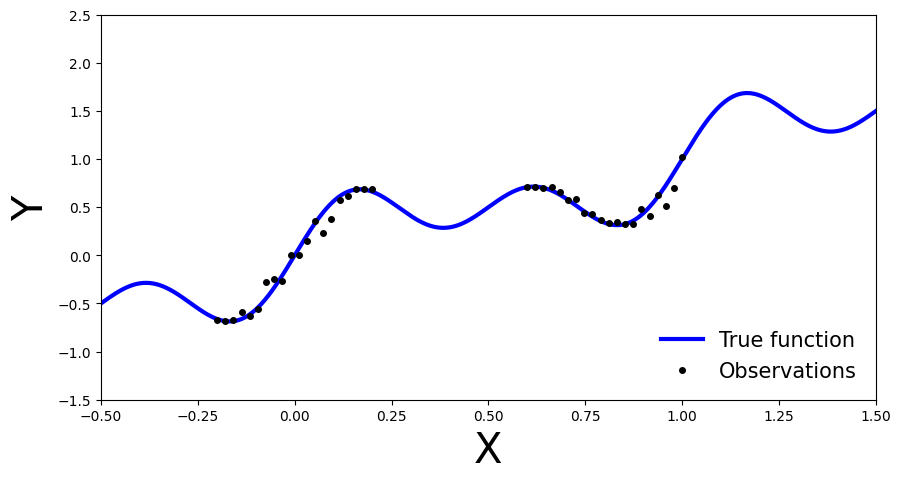

In [18]:


# Set random seed for reproducibility
np.random.seed(42)

nobs = 40

# Generate data
x_obs = np.hstack([np.linspace(-0.2, 0.2, nobs // 2), np.linspace(0.6, 1, nobs // 2)])
noise = 0.02 * np.random.randn(x_obs.shape[0])
y_obs = x_obs + 0.3 * np.sin(2 * np.pi * (x_obs + noise)) + 0.3 * np.sin(4 * np.pi * (x_obs + noise)) + noise

x_true = np.linspace(-0.5, 1.5, 1000)
y_true = x_true + 0.3 * np.sin(2 * np.pi * x_true) + 0.3 * np.sin(4 * np.pi * x_true)

# Convert data to PyTorch tensors
x_train = torch.from_numpy(x_obs).float()
y_train = torch.from_numpy(y_obs).float()

# Set plot limits and labels
xlims = [-0.5, 1.5]
ylims = [-1.5, 2.5]

x_test = torch.linspace(xlims[0], xlims[1], 3000)

# Create plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_true, y_true, 'b-', linewidth=3, label="True function")
ax.plot(x_obs, y_obs, 'ko', markersize=4, label="Observations")
ax.set_xlim(xlims)
ax.set_ylim(ylims)
ax.set_xlabel("X", fontsize=30)
ax.set_ylabel("Y", fontsize=30)
ax.legend(loc=4, fontsize=15, frameon=False)

plt.show()


x_train2 = x_train.reshape((*x_train.shape, 1))
y_train2 = y_train.reshape((*y_train.shape, 1))
x_test2 = x_test.reshape((*x_test.shape, 1))

# Insert missing data
#y_train2[range(nobs//4), 0] = torch.nan
#y_train2[range(-nobs//4, 0), 0] = torch.nan

In [19]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    while nonimproved < max_nonimproved:
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= 2 * check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            reg = stats.linregress(range(2*check_interval), losses[-2*check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            logging.info("Step {} Average Elbo loss: {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
    return losses

In [20]:
def plot_predictions(preds):
    y_pred = preds['obs'].T.detach().numpy().mean(axis=1)
    y_std = preds['obs'].T.detach().numpy().std(axis=1)

    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [-0.5, 1.5]
    ylims = [-1.5, 2.5]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)

    ax.plot(x_true, y_true, 'b-', linewidth=3, label="true function")
    ax.plot(x_obs, y_obs, 'ko', markersize=4, label="observations")
    ax.plot(x_obs, y_obs, 'ko', markersize=3)
    ax.plot(x_test, y_pred, '-', linewidth=3, color="#408765", label="predictive mean")
    ax.fill_between(x_test, y_pred - 2 * y_std, y_pred + 2 * y_std, alpha=0.6, color='#86cfac', zorder=5)

    plt.legend(loc=4, fontsize=15, frameon=False)

def plot_predictions2(preds, site="mu_pred"):


    y_pred = preds[site].squeeze().T.detach().numpy().mean(axis=1)
    y_std = preds[site].squeeze().T.detach().numpy().std(axis=1)

    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [-0.5, 1.5]
    ylims = [-1.5, 2.5]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)

    ax.plot(x_true, y_true, 'b-', linewidth=3, label="true function")
    ax.plot(x_obs, y_obs, 'ko', markersize=4, label="observations")
    ax.plot(x_obs, y_obs, 'ko', markersize=3)
    ax.plot(x_test, y_pred, '-', linewidth=3, color="#408765", label="predictive mean")
    ax.fill_between(x_test, y_pred - 2 * y_std, y_pred + 2 * y_std, alpha=0.6, color='#86cfac', zorder=5)

    for inst in range(preds[site].shape[0]):
        y_inst = preds[site].squeeze()[inst,:]
        ax.plot(x_test, y_inst, '-', linewidth=0.5, alpha=0.5, color="red")

    plt.legend(loc=4, fontsize=15, frameon=False)

### Model parameters


In [21]:
net_width = 500
net_depth = 2
prior_variance = 0.005
fixed_scale = None

## With Custom Conditional Last Layer Guide

In [41]:
from mmbo.nn import TIBNN2, TIBNN2Guide

logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

model = TIBNN2.from_data(x_train2, y_train2, width=net_width, depth=net_depth, prior_variance = prior_variance, fixed_scale = fixed_scale)
guide = TIBNN2Guide(model, init_style="prior")

adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
svi = pyro.infer.SVI(model, guide, adam, elbo)

start = timer()
losses = do_svi(svi, X_train = x_train2, Y_train = y_train2, check_interval = 500)
end = timer()

print(f"Elapsed time: {end-start:.1f} seconds")

Step 1000 Average Elbo loss: 1489.2 (slope = 128.270 +/- 29.042 loss/k-iter, p-value = 1.000) *
Step 1500 Average Elbo loss: 1490.6 (slope = 5.664 +/- 12.237 loss/k-iter, p-value = 0.823) **
Step 2000 Average Elbo loss: 1493.4 (slope = 3.392 +/- 12.278 loss/k-iter, p-value = 0.710) ***


Elapsed time: 144.5 seconds


In [45]:
start = timer()
losses = do_svi(svi, X_train = x_train2, Y_train = y_train2, check_interval = 500)
end = timer()

print(f"Elapsed time: {end-start:.1f} seconds")

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")
Step 1000 Average Elbo loss: 1491.5 (slope = 1.331 +/- 12.436 loss/k-iter, p-value = 0.585) *
Step 1500 Average Elbo loss: 1492.9 (slope = 2.522 +/- 12.322 loss/k-iter, p-value = 0.659) **
Step 2000 Average Elbo loss: 1490.7 (slope = -2.322 +/- 12.263 loss/k-iter, p-value = 0.352) ***


Elapsed time: 148.9 seconds


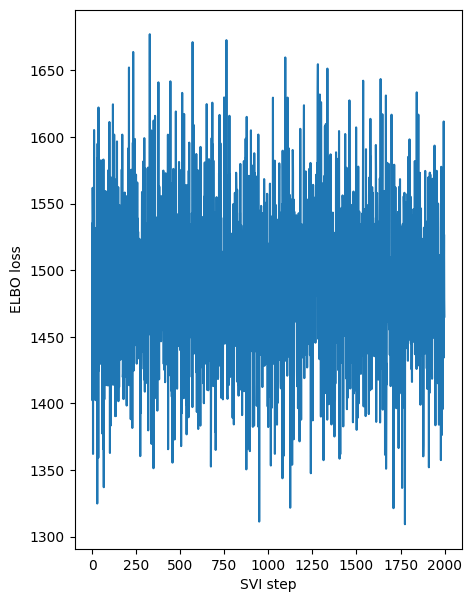

In [46]:
plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

1491.7570368493796 55.94836827977972


(array([  5.,  21.,  54., 142., 221., 253., 178.,  91.,  22.,  13.]),
 array([1309.26542401, 1344.30489504, 1379.34436607, 1414.3838371 ,
        1449.42330813, 1484.46277916, 1519.50225019, 1554.54172122,
        1589.58119226, 1624.62066329, 1659.66013432]),
 <BarContainer object of 10 artists>)

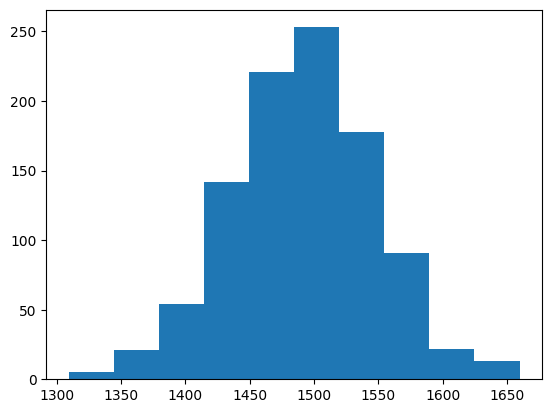

In [47]:
print(statistics.mean(losses[-1000:]), statistics.stdev(losses[-1000:]))
plt.hist(losses[-1000:])

In [24]:
for name,node in pyro.poutine.trace(guide).get_trace(X_train = x_train2, Y_train = y_train2).nodes.items():
    if node['type'] == "sample":
        print(f"{name}: {node['value'].shape}")

layer0/weight: torch.Size([500, 1])
layer0/bias: torch.Size([500])
layer0/scale: torch.Size([])
layer1/weight: torch.Size([500, 500])
layer1/bias: torch.Size([500])
layer1/scale: torch.Size([])
Y_normed_full: torch.Size([40, 1])
precision: torch.Size([1, 1])
last/full_matrix: torch.Size([1, 501])


In [25]:
svi_predictive = Predictive(model, guide=guide, num_samples=100)
svi_samples = svi_predictive(X_train = x_train2, Y_train = y_train2, X_pred = x_test2)

In [26]:
pyro.get_param_store().keys()

dict_keys(['layer_params.0.weight_loc', 'layer_params.0.weight_scale', 'layer_params.0.bias_loc', 'layer_params.0.bias_scale', 'layer_params.0.scale_loc', 'layer_params.0.scale_scale', 'layer_params.1.weight_loc', 'layer_params.1.weight_scale', 'layer_params.1.bias_loc', 'layer_params.1.bias_scale', 'layer_params.1.scale_loc', 'layer_params.1.scale_scale'])

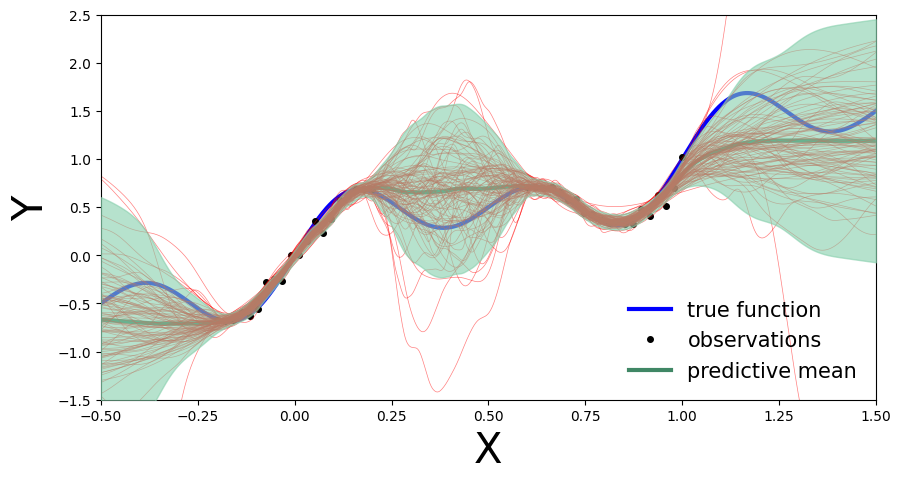

In [27]:
plot_predictions2(svi_samples, )

In [28]:
print("Average residual stdev: ", torch.linalg.inv(svi_samples["precision"]).sqrt().mean(dim=[0,1]))
print("Average last layer scale: ", svi_samples["layer1/scale"].mean(dim=[0,1]))
print("Stdev last layer scale: ", svi_samples["layer1/scale"].std(dim=[0,1]))

Average residual stdev:  tensor([[0.1536]])
Average last layer scale:  tensor(5.4840)
Stdev last layer scale:  tensor(3.2606)


In [29]:
print(pyro.get_param_store()['layer_params.1.scale_loc'])
print(pyro.get_param_store()['layer_params.1.scale_scale'])

Parameter containing:
tensor(1.5030, requires_grad=True)
tensor(0.5822, grad_fn=<AddBackward0>)


## Create custom transforms with jacobians

(Now done in mmbo package)

## Using HMC

In [30]:
model = TIBNN2.from_data(x_train2, y_train2, width=net_width, depth=net_depth, prior_variance = prior_variance, fixed_scale = fixed_scale)
nuts = NUTS(model.no_missing(), jit_compile = True, full_mass = False, init_strategy = pyro.infer.autoguide.init_to_sample)
mcmc = MCMC(nuts, num_samples = 100, warmup_steps = 100, num_chains = 1, mp_context = "spawn")
start = timer()
mcmc.run(X_train = x_train2, Y_train = y_train2)
end = timer()
print(f"Elapsed time: {end-start:.1f} seconds")

Warmup:   0%|          | 0/200 [00:00, ?it/s]/home/itaylor/projects/mmbo/src/mmbo/nn/network.py:146: TracerWarning: Converting a tensor to a Python float might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  dist.Normal(0, 1 / math.sqrt(insize)).expand((outsize, insize)).to_event(2)
/home/itaylor/projects/mmbo/src/mmbo/nn/network.py:146: TracerWarning: Converting a tensor to a Python float might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  dist.Normal(0, 1 / math.sqrt(insize)).expand((outsize, insize)).to_event(2)
/home/itaylor/projects/mmbo/src/mmbo/dist.py:118: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record t

Elapsed time: 936.4 seconds


In [31]:
mcmc_predictive = Predictive(model, posterior_samples=mcmc.get_samples())
mcmc_pred_samples = mcmc_predictive(X_train = x_train2, Y_train = y_train2, X_pred = x_test2)

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


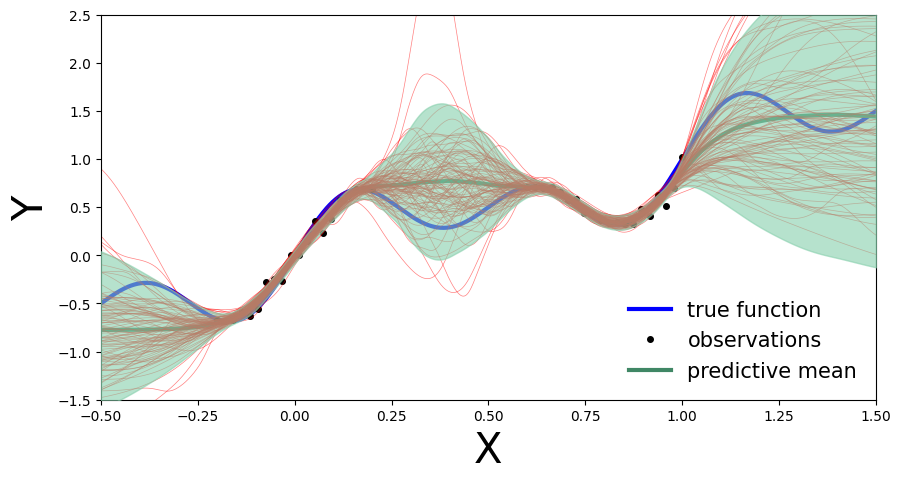

In [32]:
plot_predictions2(mcmc_pred_samples)

In [33]:
print("Average residual stdev: ", torch.linalg.inv(mcmc.get_samples()["precision"]).sqrt().mean(dim=[0]))
print("Average last layer scale: ", mcmc.get_samples()["layer1/scale"].mean(dim=[0]))

Average residual stdev:  tensor([[0.1735]])
Average last layer scale:  tensor(3.9016)


## With diagonal normal guide

In [35]:
logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.set_rng_seed(12)

pyro.clear_param_store()

model = TIBNN2.from_data(x_train2, y_train2, width=net_width, depth=net_depth, prior_variance = prior_variance, fixed_scale = fixed_scale)
guide = pyro.infer.autoguide.AutoNormal(model.no_missing(), init_loc_fn=pyro.infer.autoguide.init_to_sample)

adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
svi = pyro.infer.SVI(model.no_missing(), guide, adam, elbo)

start = timer()
losses = do_svi(svi, X_train = x_train2, Y_train = y_train2, check_interval = 500)
end = timer()

print(f"Elapsed time: {end-start:.1f} seconds")

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")
Step 1000 Average Elbo loss: 370719.6 (slope = -169123.439 +/- 8563.185 loss/k-iter, p-value = 0.000) 
Step 1500 Average Elbo loss: 301133.5 (slope = -140280.796 +/- 4901.011 loss/k-iter, p-value = 0.000) 
Step 2000 Average Elbo loss: 246654.0 (slope = -108699.425 +/- 2770.427 loss/k-iter, p-value = 0.000) 
Step 2500 Average Elbo loss: 203821.6 (slope = -86320.649 +/- 1822.347 loss/k-iter, p-value = 0.000) 
Step 3000 Average Elbo loss: 167817.5 (slope = -72128.456 +/- 1231.000 loss/k-iter, p-value = 0.000) 
Step 3500 Average Elbo loss: 136206.4 (slope = -62883.147 +/- 812.616 loss/k-iter, p-value = 0.000) 
Step 4000 Average Elbo loss: 107758.0 (slope = -56689.624 +/- 502.672 loss/k-iter, p-value = 0.000) 
Step 4500 Average Elbo loss: 83378.0 (slope = -48782.597 +/- 321.145 loss/k-iter, p-value = 0.000) 
St

Elapsed time: 916.8 seconds


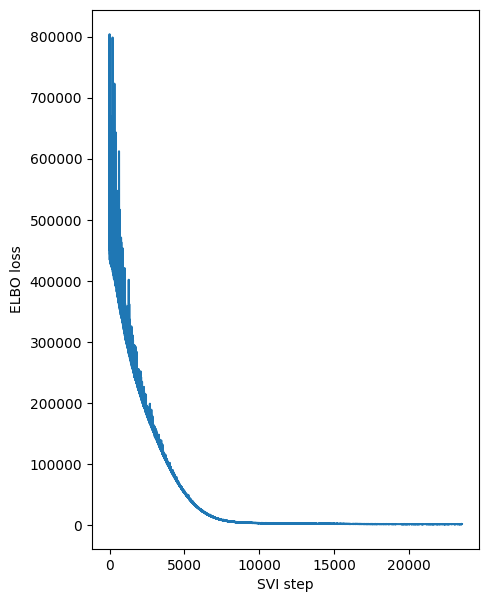

In [36]:
plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

In [37]:
svi_predictive = Predictive(model, guide=guide, num_samples=100)
svi_samples = svi_predictive(X_train = x_train2, Y_train = y_train2, X_pred = x_test2)

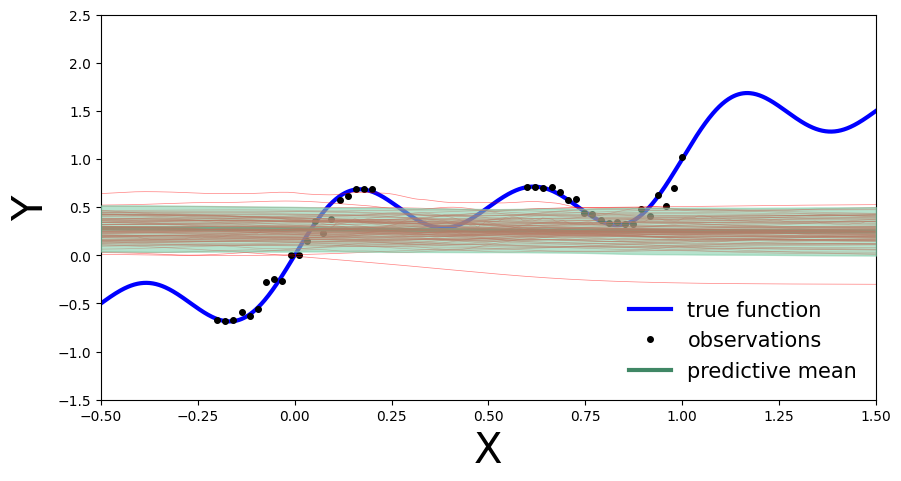

In [38]:
plot_predictions2(svi_samples)

In [39]:
print("Average residual stdev: ", torch.linalg.inv(svi_samples["precision"]).sqrt().mean(dim=[0,1]))
print("Average last layer scale: ", svi_samples["layer1/scale"].mean(dim=[0,1]))

Average residual stdev:  tensor([[0.6418]])
Average last layer scale:  tensor(0.0206)
